# Machine Learning with Tabular Data: Diabetes Readmission Prediction

**Objective:** The primary goal of this project is to build a traditional machine learning pipeline to predict hospital readmission for diabetic patients. Predicting whether a patient will be readmitted within 30 days (`<30`), after 30 days (`>30`), or not at all (`NO`) is critical for optimizing hospital resources and improving patient care.

**Pipeline Overview:** Following the assignment constraints, this notebook implements a fully configurable machine learning pipeline consisting of:
1. Exploratory Data Analysis (EDA)
2. Data Preprocessing & Feature Engineering
3. Feature Extraction (PCA)
4. Model Training (Logistic Regression, SVM, Random Forest)
5. Model Evaluation


# Phase 1 - EDA

## 1.1 Dowload and Extract dataset

In [1]:
import os
import sys
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [34]:
# Project directories
if 'google.colab' in sys.modules:
    print("Running on Google Colab")
    PROJECT_DIR = Path("/content/ml_assignment")
else:
    print("Running on Local Machine")
    PROJECT_DIR = Path.cwd() / "ml_assignment"

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
MODULES_DIR = PROJECT_DIR / "modules"
REPORTS_DIR = PROJECT_DIR / "reports"
FEATURES_DIR = PROJECT_DIR / "features"

for d in [DATA_DIR, RAW_DIR, MODULES_DIR, REPORTS_DIR, FEATURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print(f"Project directory set to: {PROJECT_DIR}")

Running on Local Machine
Project directory set to: d:\HCMUT\5th_Semester\ML\Assignment\ml_assignment


In [3]:
# Dowload dataset
DATA_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

ZIP_PATH = DATA_DIR / "diabetes.zip"

if not ZIP_PATH.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Download completed.")
else:
    print("Dataset archive already exists. Skipping download.")

Dataset archive already exists. Skipping download.


In [4]:
# Extract dataset
if not list(RAW_DIR.glob("*.csv")):
    print("Extracting files...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(RAW_DIR)
    print("Extraction completed.")
else:
    print("Files already extracted.")
print("\nFiles in raw directory:")
for path in RAW_DIR.rglob("*"):
    if path.is_file():
        print(f" - {path.name}")

Files already extracted.

Files in raw directory:
 - diabetic_data.csv
 - IDS_mapping.csv


## 1.2 Load Dataset

In [5]:
DATA_PATH = RAW_DIR / "diabetic_data.csv"

df = pd.read_csv(DATA_PATH, na_values=['?'])

print("DATASET LOADED SUCCESSFULLY")
print(f"Shape: {df.shape}")

DATASET LOADED SUCCESSFULLY
Shape: (101766, 50)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10860\2679753223.py:3: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH, na_values=['?'])


In [6]:
print(f"Dataset shape:{df.shape}")
print(f"Number of rows:{df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset shape:(101766, 50)
Number of rows:101,766
Number of columns: 50


In [7]:
# Columns names
print("COLUMN NAMES")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

COLUMN NAMES
 1. encounter_id
 2. patient_nbr
 3. race
 4. gender
 5. age
 6. weight
 7. admission_type_id
 8. discharge_disposition_id
 9. admission_source_id
10. time_in_hospital
11. payer_code
12. medical_specialty
13. num_lab_procedures
14. num_procedures
15. num_medications
16. number_outpatient
17. number_emergency
18. number_inpatient
19. diag_1
20. diag_2
21. diag_3
22. number_diagnoses
23. max_glu_serum
24. A1Cresult
25. metformin
26. repaglinide
27. nateglinide
28. chlorpropamide
29. glimepiride
30. acetohexamide
31. glipizide
32. glyburide
33. tolbutamide
34. pioglitazone
35. rosiglitazone
36. acarbose
37. miglitol
38. troglitazone
39. tolazamide
40. examide
41. citoglipton
42. insulin
43. glyburide-metformin
44. glipizide-metformin
45. glimepiride-pioglitazone
46. metformin-rosiglitazone
47. metformin-pioglitazone
48. change
49. diabetesMed
50. readmitted


In [8]:
# Print first 5 rows
display(df.head())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [9]:
# Data type
display(df.dtypes.to_frame(name="dtype"))

,dtype
encounter_id,int64
patient_nbr,int64
race,str
gender,str
age,str
weight,str
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64


## 1.3 Dataset Overview - Numerical & Categorical

In [35]:
print("=" * 60)
print("DATASET OVERVIEW - NUMERICAL & CATEGORICAL")
print("=" * 60)

# Keep encounter_id numeric so chronological sorting remains numeric later.
# Categorical ID columns are converted to strings to avoid treating them as measurements.
id_cols = ['patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df[id_cols] = df[id_cols].astype(str)

# Observe overall distribution
display(df.describe(include="all").T)

DATASET OVERVIEW - NUMERICAL & CATEGORICAL


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766,101766,2278392,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_nbr,101766,71518,88785891,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766,8,1,53990,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discharge_disposition_id,101766,26,1,60234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_source_id,101766,17,7,57494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


## 1.4 Missing Value Analysis

MISSING VALUES ANALYSIS


,Missing_Count,Percentage (%)
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


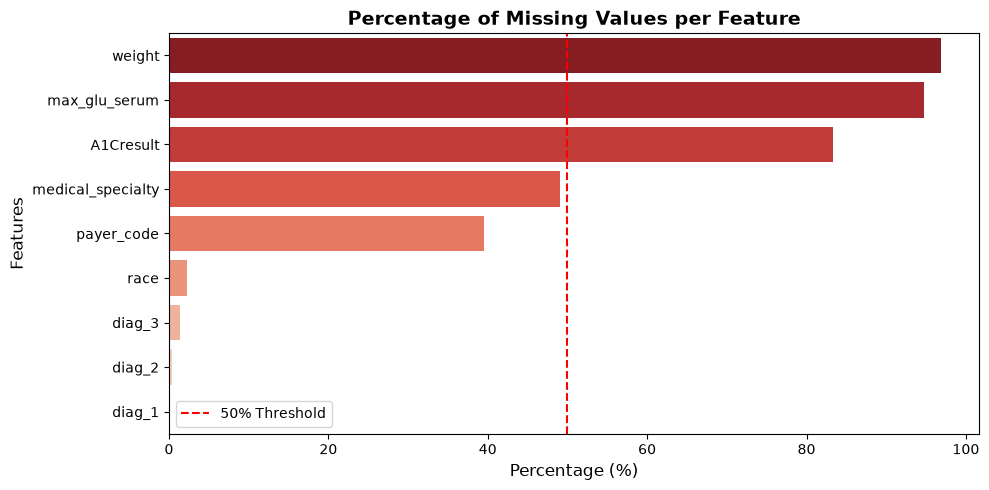

In [11]:
print("=" * 60)
print("MISSING VALUES ANALYSIS")
print("=" * 60)

# Since Pandas automatically parsed '?' as NaN during dataset loading, we only need one line of code for computation
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing_Count': missing_count, 
    'Percentage (%)': missing_percent
})

# Filter columns with missing values and sort them
missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Percentage (%)', ascending=False)
display(missing_summary)

# BONUS: Plot a bar chart for easy inclusion in the PDF report (Huge bonus points)
if not missing_summary.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_summary['Percentage (%)'], y=missing_summary.index, hue=missing_summary.index, palette='Reds_r', legend=False)
    plt.title('Percentage of Missing Values per Feature', fontsize=14, fontweight='bold')
    plt.xlabel('Percentage (%)', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.axvline(x=50, color='r', linestyle='--', label='50% Threshold') # Warning threshold line
    plt.legend()
    plt.tight_layout()
    plt.show()

## 1.5 Duplicate Analysis

In [12]:
print("=" * 60)
print("DUPLICATE & PATIENT ENCOUNTER ANALYSIS")
print("=" * 60)

# Check for completely duplicated rows
duplicate_count = df.duplicated().sum()
print(f"Total fully duplicated rows: {duplicate_count}")

# BONUS: Check if a single patient has multiple encounters (readmissions)
unique_patients = df['patient_nbr'].nunique()
total_encounters = len(df)
multiple_encounters = total_encounters - unique_patients

print(f"Total encounters (rows): {total_encounters:,}")
print(f"Total unique patients: {unique_patients:,}")
print(f"Number of return visits (multiple encounters): {multiple_encounters:,}")


DUPLICATE & PATIENT ENCOUNTER ANALYSIS
Total fully duplicated rows: 0
Total encounters (rows): 101,766
Total unique patients: 71,518
Number of return visits (multiple encounters): 30,248


## 1.6 Target Distribution

In [13]:
TARGET = "readmitted"

# Count each target class
target_counts = df[TARGET].value_counts()

# Calculate percentages
target_percentages = df[TARGET].value_counts(normalize=True) * 100

# Combine into one summary table
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

print("=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

display(target_summary)

TARGET DISTRIBUTION


,count,percentage
readmitted,,
NO,54864,53.911916
>30,35545,34.928169
<30,11357,11.159916


Target Distribution Visualization

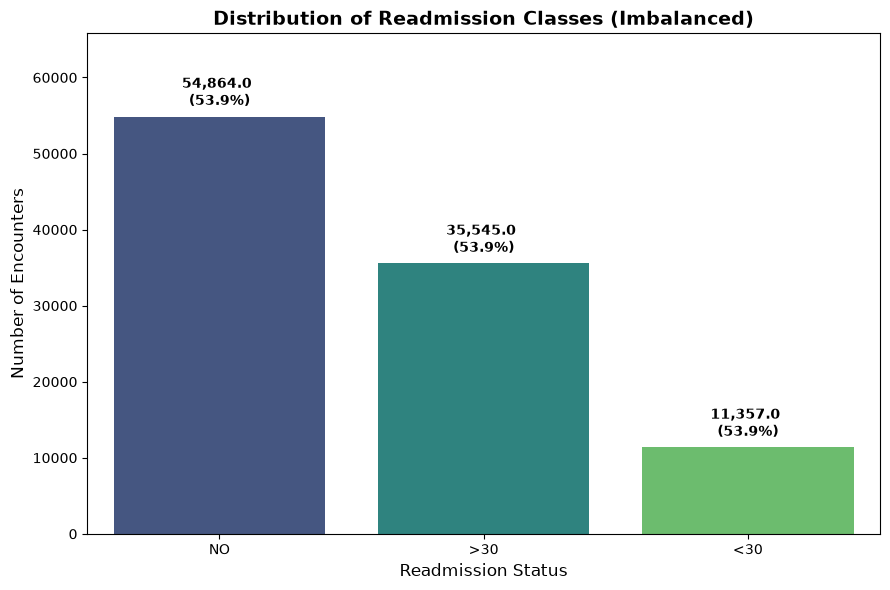

In [14]:
# Visualization
plt.figure(figsize=(9, 6))
# Use 'viridis' palette for better aesthetic, assign x to hue to avoid warnings

ax = sns.countplot(data=df, x=TARGET, order=target_counts.index, hue=TARGET, palette='viridis', legend=False)
plt.title("Distribution of Readmission Classes (Imbalanced)", fontsize=14, fontweight='bold')
plt.xlabel("Readmission Status", fontsize=12)
plt.ylabel("Number of Encounters", fontsize=12)

# Add both count and percentage labels on top of the bars
for i, container in enumerate(ax.containers):
    labels = [f'{v.get_height():,} \n({target_percentages.iloc[j]:.1f}%)' for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, padding=5, fontweight='bold')

# Expand y-axis slightly to fit the tall labels
plt.ylim(0, target_counts.max() * 1.2)
plt.tight_layout()
plt.show()

## 1.7 Categorical Features Overview

In [15]:
TARGET = "readmitted"

print("=" * 60)
print("CATEGORICAL FEATURES SUMMARY (CARDINALITY & DOMINANCE)")
print("=" * 60)

# Extract categorical columns (including 'object' and 'string' to avoid Pandas warnings)
categorical_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

# Exclude target variable and identifier columns from the categorical analysis
cols_to_exclude = [TARGET, "encounter_id", "patient_nbr"]
categorical_features = [c for c in categorical_cols if c not in cols_to_exclude]

# Aggregate cardinality and dominance information into a single DataFrame
cat_summary_list = []
for col in categorical_features:
    # Temporarily fill NaN values with 'Missing' for better visualization in the summary table
    temp_col = df[col].fillna("Missing")
    unique_count = temp_col.nunique()
    
    val_counts = temp_col.value_counts()
    dominant_val = val_counts.index[0]
    dominant_pct = (val_counts.iloc[0] / len(df)) * 100
    
    cat_summary_list.append({
        "Feature": col,
        "Unique_Values": unique_count,
        "Dominant_Value": dominant_val,
        "Dominant_Pct (%)": dominant_pct
    })

# Sort the summary by dominant percentage in descending order
cat_summary = pd.DataFrame(cat_summary_list).sort_values(by="Dominant_Pct (%)", ascending=False)
display(cat_summary)

# Highlight near-constant features (>95% same value)
near_constant = cat_summary[cat_summary["Dominant_Pct (%)"] > 95]
print(f"\n[WARNING]: Detected {len(near_constant)} near-constant features (Dominant Percentage > 95%).")
print("-> These features provide little to no variance and should be dropped during Data Preprocessing.")


CATEGORICAL FEATURES SUMMARY (CARDINALITY & DOMINANCE)


,Feature,Unique_Values,Dominant_Value,Dominant_Pct (%)
30,citoglipton,1,No,100.000000
29,examide,1,No,100.000000
19,acetohexamide,2,No,99.999017
36,metformin-pioglitazone,2,No,99.999017
34,glimepiride-pioglitazone,2,No,99.999017
35,metformin-rosiglitazone,2,No,99.998035
27,troglitazone,2,No,99.997052
33,glipizide-metformin,2,No,99.987226
22,tolbutamide,2,No,99.977399
26,miglitol,4,No,99.962659



[WARNING]: Detected 17 near-constant features (Dominant Percentage > 95%).
-> These features provide little to no variance and should be dropped during Data Preprocessing.


DISTRIBUTION OF KEY CATEGORICAL FEATURES


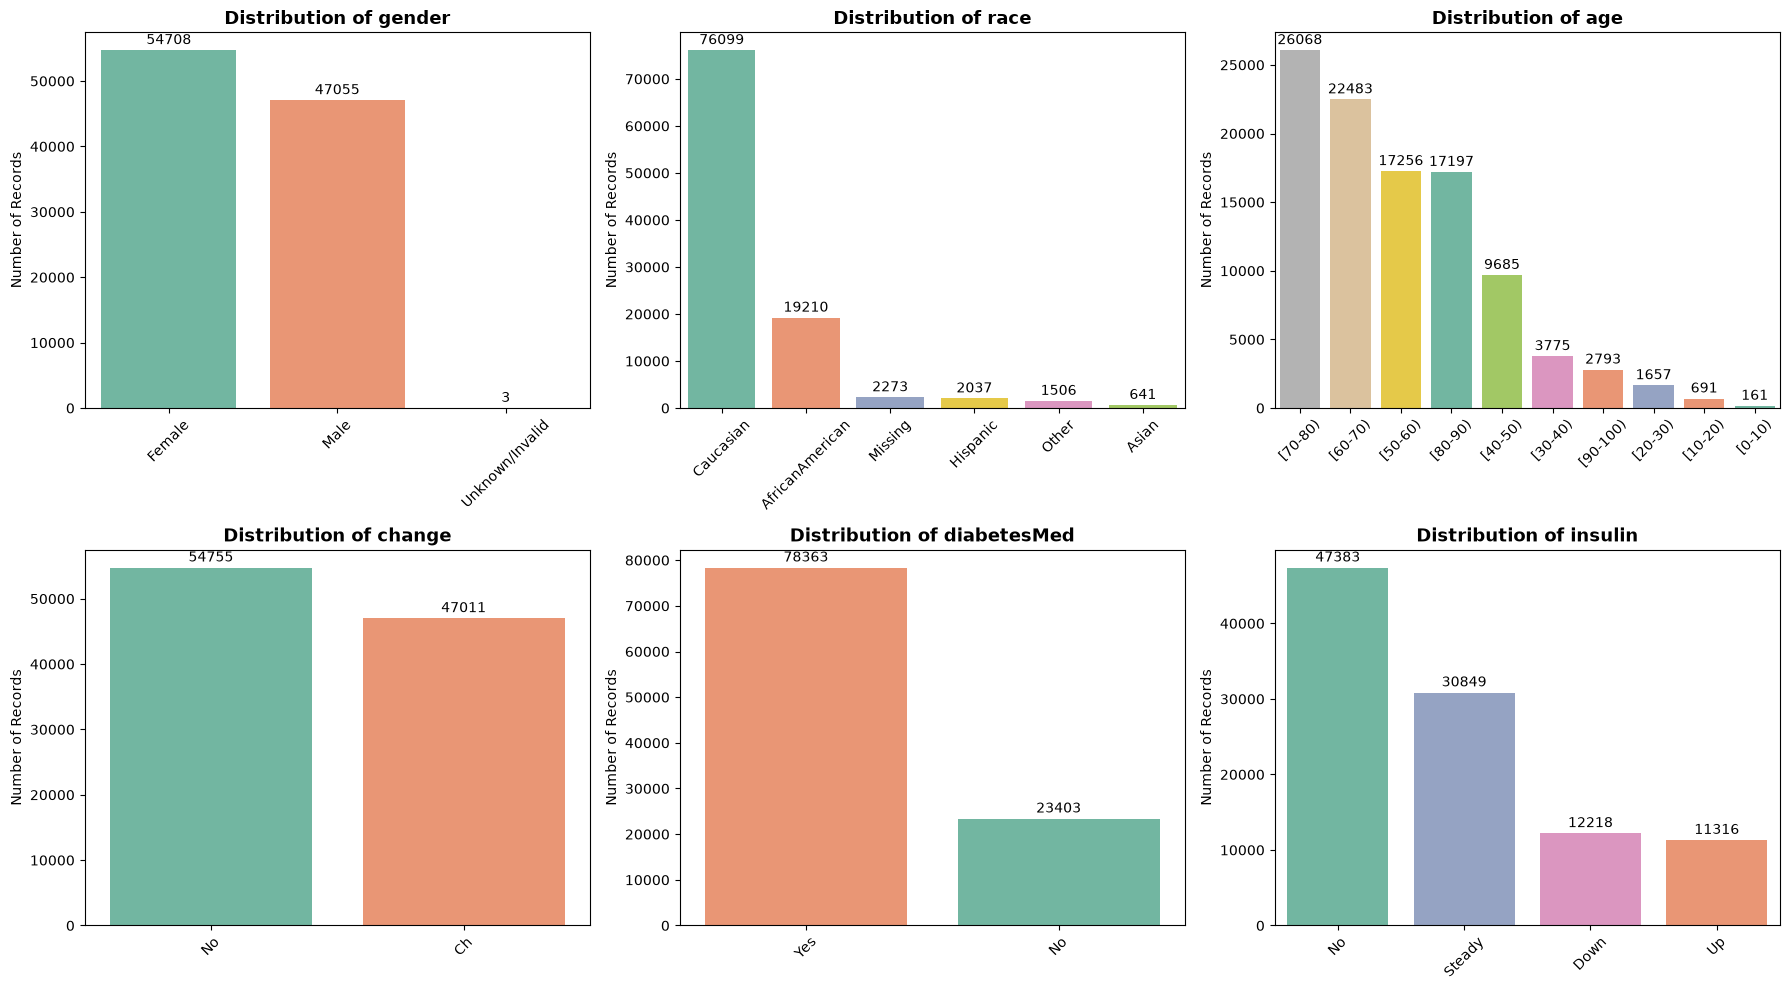

In [16]:
print("=" * 60)
print("DISTRIBUTION OF KEY CATEGORICAL FEATURES")
print("=" * 60)

# Select key categorical features for visualization
key_categorical_features = ["gender", "race", "age", "change", "diabetesMed", "insulin"]

# Create a 2x3 subplot grid for a better layout
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(key_categorical_features):
    ax = axes[i]
    
    # Fill NaN values with "Missing" and cast to string to prevent Seaborn mixed-type errors
    plot_data = df[col].fillna("Missing").astype(str)
    
    # Plot count chart with automatic color differentiation
    sns.countplot(
        x=plot_data, 
        order=plot_data.value_counts().index, 
        ax=ax,
        hue=plot_data,   
        palette='Set2',  
        legend=False
    )
    
    ax.set_title(f"Distribution of {col}", fontsize=13, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Number of Records")
    ax.tick_params(axis="x", rotation=45)
    
    # Add exact count labels on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', padding=2, fontsize=10)

plt.tight_layout()
plt.show()


## 1.8 Numerical Features

NUMERICAL FEATURES DISTRIBUTION & OUTLIERS


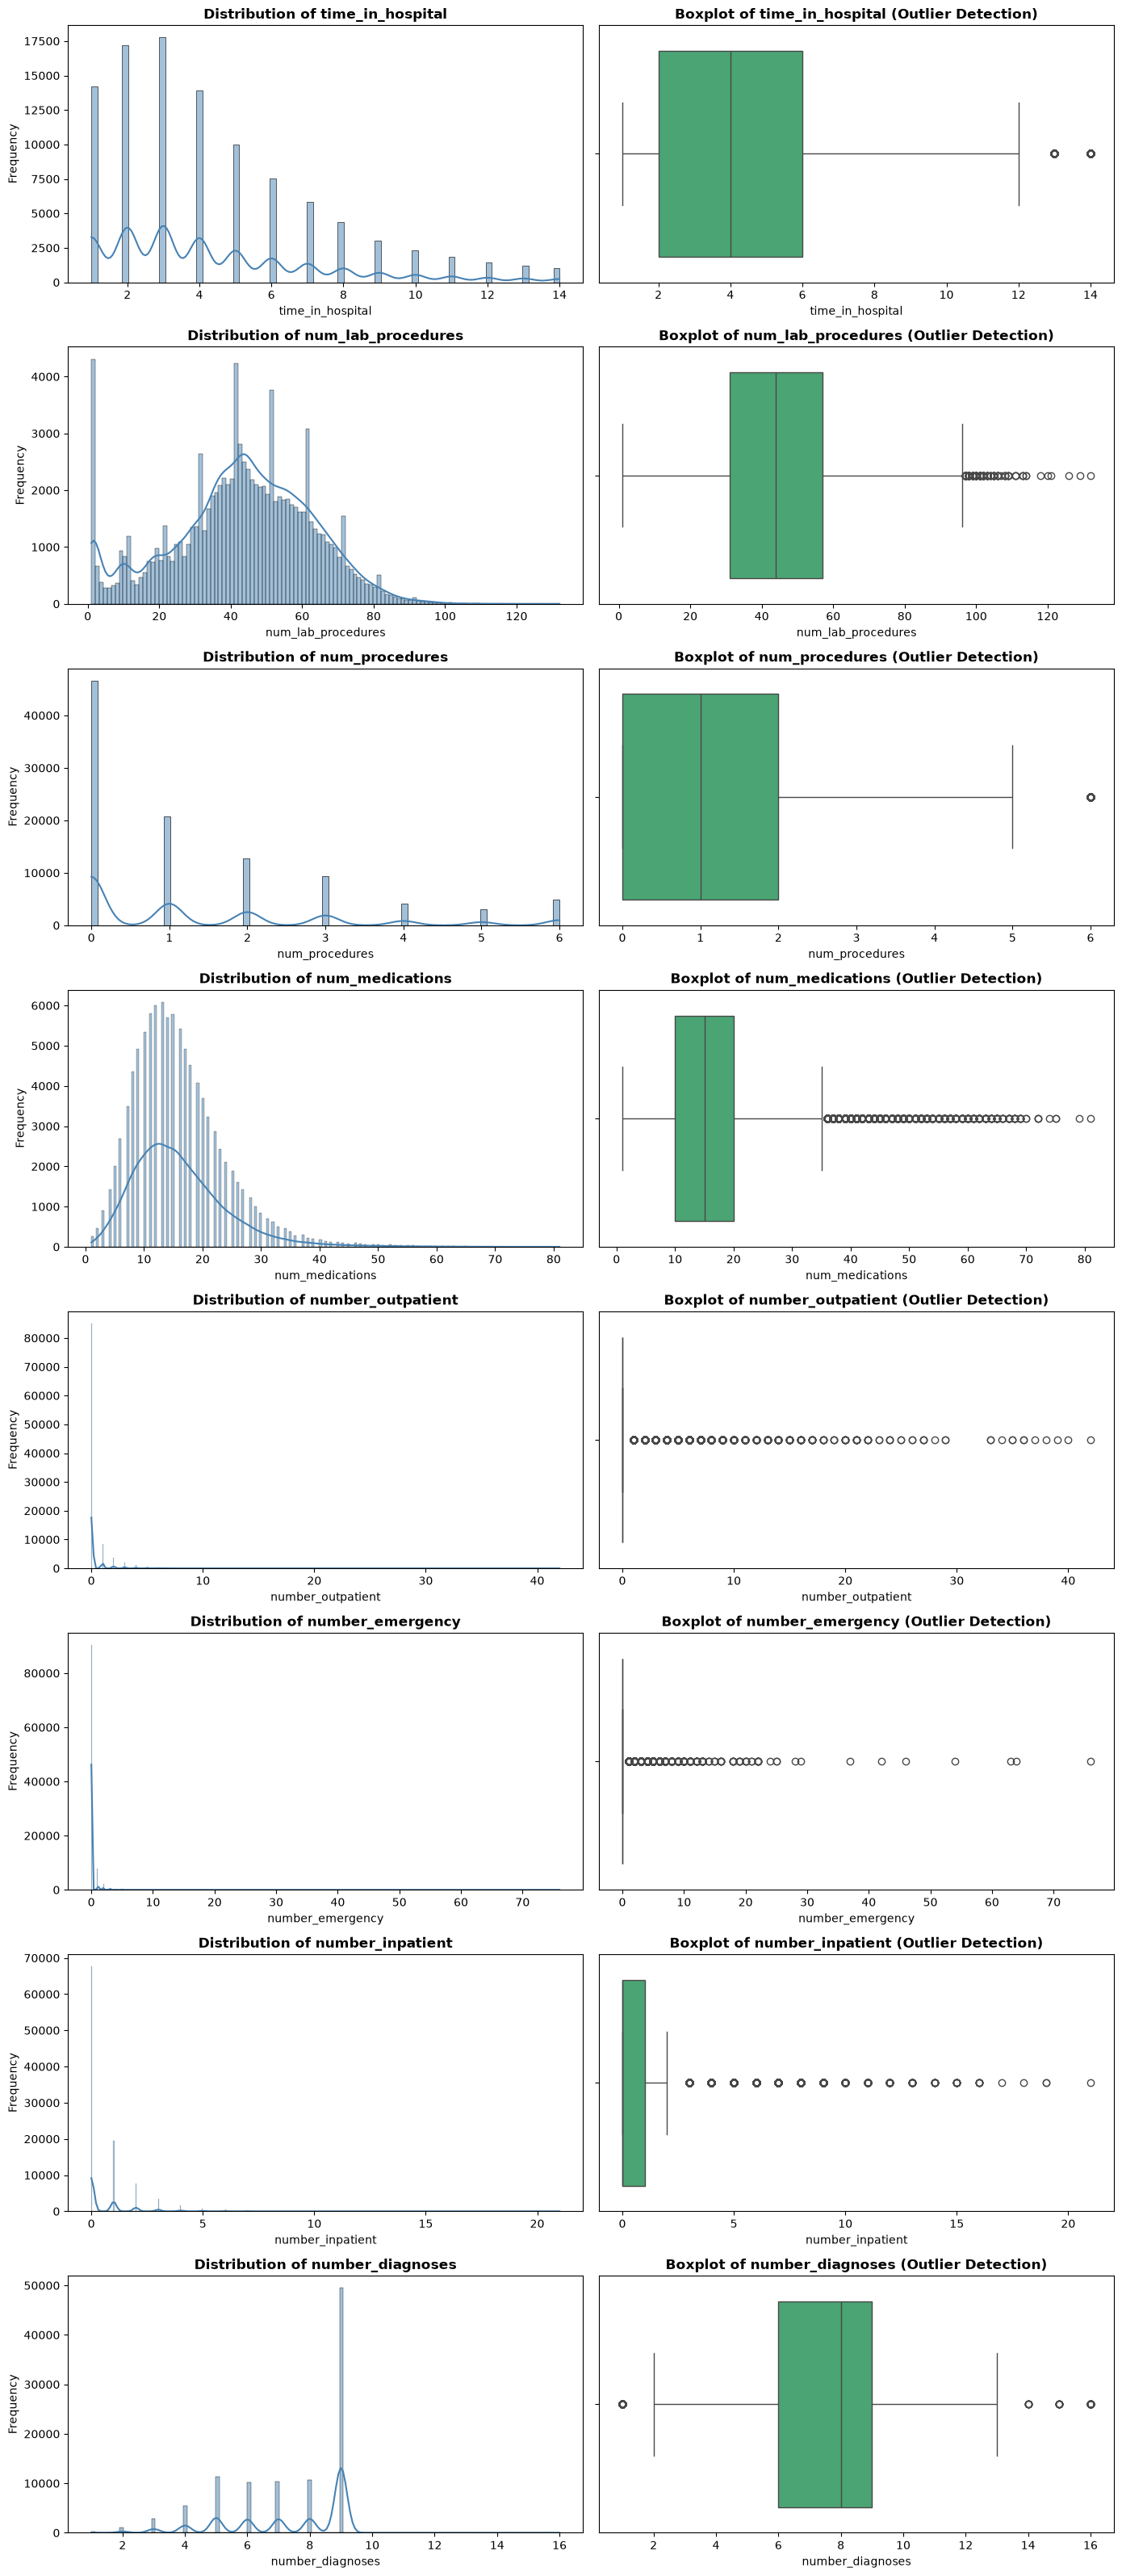

In [17]:
print("=" * 60)
print("NUMERICAL FEATURES DISTRIBUTION & OUTLIERS")
print("=" * 60)

# Automatically identify numerical columns (excluding IDs since we casted them to string in 1.3)
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Create subplots: Left side for Histogram, Right side for Boxplot
fig, axes = plt.subplots(len(numerical_cols), 2, figsize=(14, 4 * len(numerical_cols)))

for i, col in enumerate(numerical_cols):
    # Histogram for Data Distribution
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='steelblue')
    axes[i, 0].set_title(f'Distribution of {col}', fontweight='bold')
    axes[i, 0].set_ylabel('Frequency')
    
    # Boxplot for Outlier Detection
    sns.boxplot(x=df[col], ax=axes[i, 1], color='mediumseagreen')
    axes[i, 1].set_title(f'Boxplot of {col} (Outlier Detection)', fontweight='bold')

plt.tight_layout()
plt.show()


## 1.9 Correlation Heatmap

CORRELATION MATRIX (NUMERICAL FEATURES)


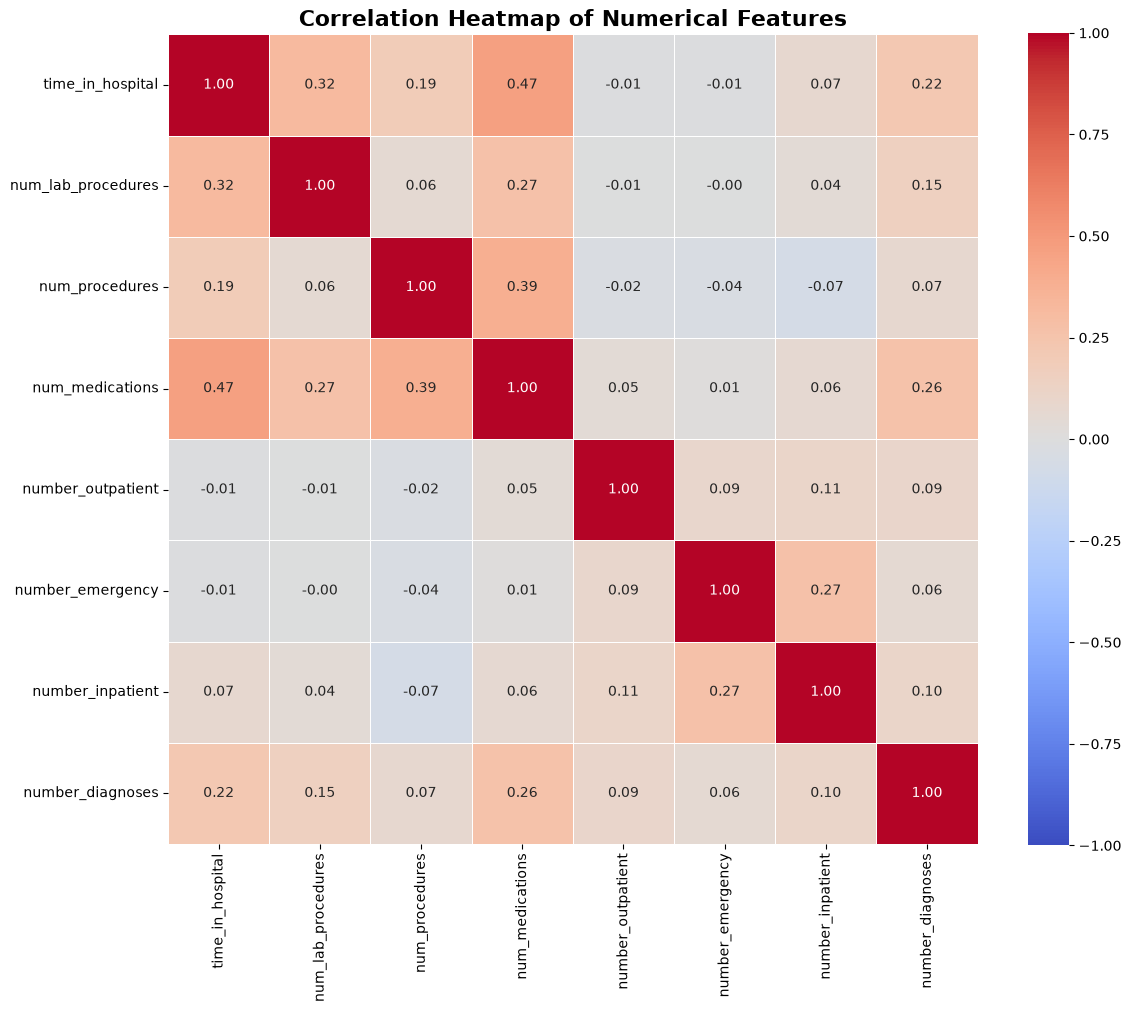

In [18]:
print("=" * 60)
print("CORRELATION MATRIX (NUMERICAL FEATURES)")
print("=" * 60)

plt.figure(figsize=(12, 10))

# Calculate Pearson correlation matrix for numerical columns
corr_matrix = df[numerical_cols].corr()

# Plot Heatmap
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    square=True, 
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


1.10 BIVARIATE ANALYSIS: FEATURES VS TARGET


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10860\3015724662.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y='time_in_hospital', palette='Set2', ax=axes[0])


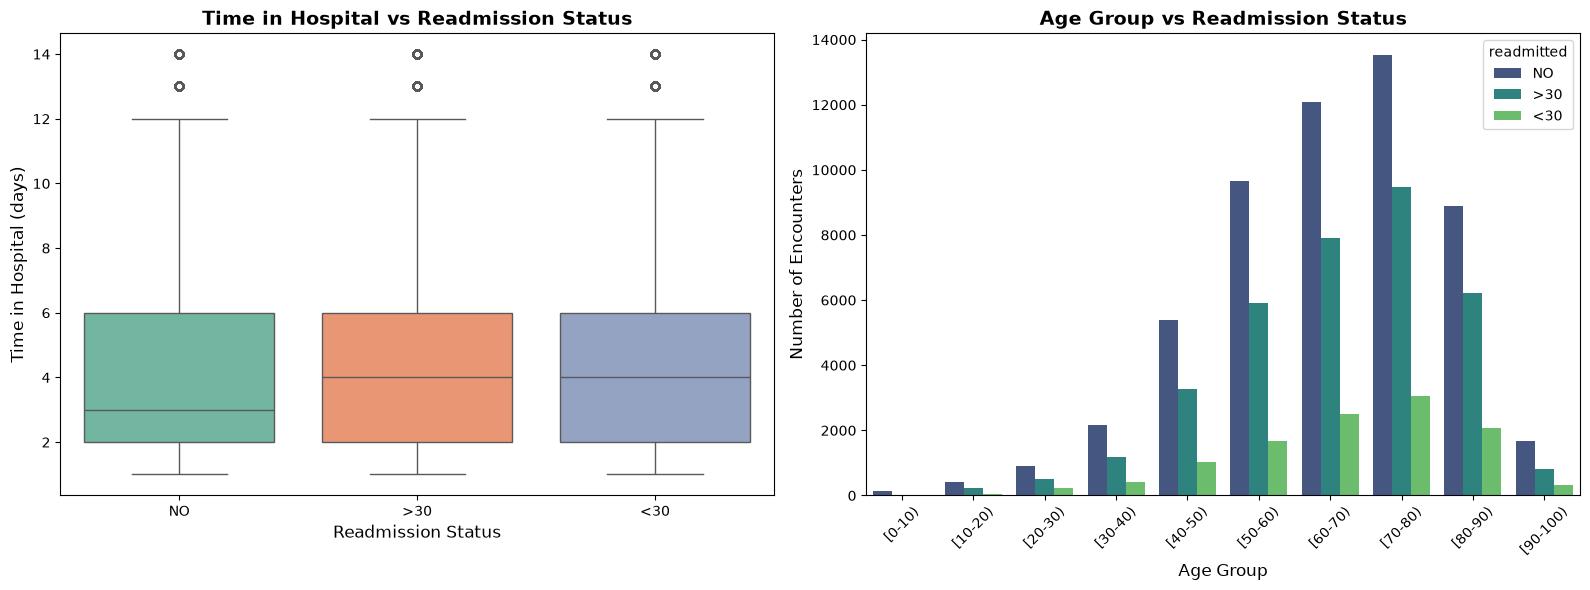

In [19]:
print("=" * 60)
print("1.10 BIVARIATE ANALYSIS: FEATURES VS TARGET")
print("=" * 60)

# Create a figure with 2 subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Numerical Feature vs Target (Boxplot)
# Question: Does 'time_in_hospital' differ across readmission statuses?
sns.boxplot(data=df, x=TARGET, y='time_in_hospital', palette='Set2', ax=axes[0])
axes[0].set_title('Time in Hospital vs Readmission Status', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Readmission Status', fontsize=12)
axes[0].set_ylabel('Time in Hospital (days)', fontsize=12)

# 2. Categorical Feature vs Target (Countplot)
# Question: Does 'age' impact readmission rates?
sns.countplot(data=df, x='age', hue=TARGET, palette='viridis', ax=axes[1])
axes[1].set_title('Age Group vs Readmission Status', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Age Group', fontsize=12)
axes[1].set_ylabel('Number of Encounters', fontsize=12)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 1.11 EDA Summary and Key Insights

Based on our Exploratory Data Analysis, we have identified several critical data characteristics that will dictate our preprocessing and modeling strategies:

1. **Target Variable (`readmitted`) - Imbalanced Classification:**
   - The target is highly imbalanced. The majority of patients are not readmitted (`NO`: ~54%), while the most critical class for hospitals (readmission `<30` days) represents only ~11% of the data. 
   - **Action:** We must use Stratified Sampling during the train-test split. Evaluation metrics should prioritize F1-score, Precision-Recall AUC, or ROC-AUC rather than raw Accuracy.

2. **Data Leakage & Patient Independence (CRITICAL):**
   - Out of 101,766 encounters, there are only 71,518 unique patients. This indicates that roughly 30% of the dataset consists of repeat visits.
   - **Action:** To prevent **Data Leakage** (where a model memorizes patient-specific traits from the training set to predict on the test set), we must only keep the *first encounter* for each patient.
   - **Clinical Logic Filter:** Patients who were discharged to hospice or passed away (specific `discharge_disposition_id` codes like 11, 13, 14, 19, 20, 21) cannot physically be readmitted. Including them would bias the model, hence they must be removed.

3. **Missing Values Handling:**
   - `weight` is missing in ~97% of records. It provides almost no information and should be dropped entirely.
   - `medical_specialty` (~49% missing) and `payer_code` (~40% missing) require careful imputation (e.g., filling with "Unknown") to treat the absence of information as a valid categorical feature.

4. **Zero-Variance / Near-Constant Features:**
   - Features such as `examide`, `citoglipton`, and several medication columns are dominated by a single value (>95% "No"). 
   - **Action:** These features offer no discriminatory power for the machine learning model and should be dropped to reduce dimensionality and noise.

5. **Identifier Columns:**
   - `encounter_id` and `patient_nbr` are high-cardinality identifiers with no predictive value. They must be dropped prior to modeling.


# Phase 2: Data Preprocessing

In this section, we will clean the dataset by removing invalid records, handling missing values, and dropping useless features based on our EDA findings to ensure the machine learning model learns generalizable patterns.

## 2.1 & 2.2 Handling Data Leakage

In [36]:
print("=" * 60)
print("HANDLING DATA LEAKAGE (ROWS REMOVAL)")
print("=" * 60)

# CREATE A COPY TO PREVENT MODIFYING THE ORIGINAL DATA
df_clean = df.copy()

initial_shape = df_clean.shape[0]
print(f"Original number of encounters: {initial_shape:,}")

# 1. Remove Dead/Hospice Patients (Logical Leakage)
dead_hospice_ids = ['11', '13', '14', '19', '20', '21']
df_clean = df_clean[~df_clean['discharge_disposition_id'].astype(str).isin(dead_hospice_ids)]

after_death_removal = df_clean.shape[0]
print(f"Encounters after removing Dead/Hospice patients: {after_death_removal:,} (Dropped {initial_shape - after_death_removal:,})")

# 2. Remove Multiple Encounters (Patient Leakage)
# encounter_id is kept numeric in EDA, so this preserves chronological order.
df_clean = df_clean.sort_values('encounter_id').drop_duplicates(subset=['patient_nbr'], keep='first')

after_duplicate_removal = df_clean.shape[0]
print(f"Encounters after keeping only the first visit per patient: {after_duplicate_removal:,} (Dropped {after_death_removal - after_duplicate_removal:,})")

print("-" * 60)
print(f"Total rows dropped: {initial_shape - after_duplicate_removal:,}")
print(f"Current Cleaned Dataset Shape: {df_clean.shape}")

HANDLING DATA LEAKAGE (ROWS REMOVAL)
Original number of encounters: 101,766
Encounters after removing Dead/Hospice patients: 99,343 (Dropped 2,423)
Encounters after keeping only the first visit per patient: 69,990 (Dropped 29,353)
------------------------------------------------------------
Total rows dropped: 31,776
Current Cleaned Dataset Shape: (69990, 50)


## 2.3 Drop Useless Columns

In [38]:
print("=" * 60)
print("DROPPING IDENTIFIERS & HEAVILY MISSING DATA")
print("=" * 60)

initial_cols = df_clean.shape[1]

# Drop identifiers (cause data leakage / overfitting) and highly missing column ('weight')
cols_to_drop = ['encounter_id', 'patient_nbr', 'weight']
df_clean = df_clean.drop(columns=cols_to_drop, errors='ignore')

print(f"Manually dropped columns: {cols_to_drop}")
print(f"Current Cleaned Dataset Shape: {df_clean.shape}")

DROPPING IDENTIFIERS & HEAVILY MISSING DATA
Manually dropped columns: ['encounter_id', 'patient_nbr', 'weight']
Current Cleaned Dataset Shape: (69990, 47)


In [39]:
print("=" * 60)
print("IDENTIFY NEAR-CONSTANT FEATURES")
print("=" * 60)
TARGET = "readmitted"

# Identify candidates for reporting only. The actual drop is performed after
# the train-test split using X_train statistics to avoid using test data.
categorical_cols = df_clean.select_dtypes(exclude=['number']).columns.tolist()
if TARGET in categorical_cols:
    categorical_cols.remove(TARGET)

near_constant_cols = []
for col in categorical_cols:
    dominant_pct = (df_clean[col].value_counts(dropna=False).iloc[0] / len(df_clean)) * 100
    if dominant_pct > 95:
        near_constant_cols.append(col)

print(f"Identified {len(near_constant_cols)} near-constant candidates (>95% dominant):")
import pprint
pprint.pprint(near_constant_cols, compact=True)
print("Near-constant columns will be selected again from X_train after splitting.")

IDENTIFY NEAR-CONSTANT FEATURES
Identified 17 near-constant candidates (>95% dominant):
['max_glu_serum', 'repaglinide', 'nateglinide', 'chlorpropamide',
 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone',
 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin',
 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone',
 'metformin-pioglitazone']
Near-constant columns will be selected again from X_train after splitting.


In [23]:
print("=" * 60)
print("CURRENT STATE OF CLEANED DATASET (df_clean)")
print("=" * 60)

# 1. Check current shape
print(f"Dataset Shape: {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns\n")

# 2. Print general information (dtypes and non-null counts)
print("DATASET INFO:")
df_clean.info()

# 3. Summarize remaining missing values
print("\n" + "=" * 60)
print("MISSING VALUES SUMMARY (REMAINING COLUMNS)")
print("=" * 60)

# Calculate missing counts and percentages
missing_counts = df_clean.isnull().sum()
missing_pct = (missing_counts / len(df_clean)) * 100

missing_summary = pd.DataFrame({
    'Missing_Count': missing_counts,
    'Missing_Pct (%)': missing_pct
})

# Filter and display only columns that still have missing values
missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Pct (%)', ascending=False)

if missing_summary.empty:
    print("No missing values found in the current dataset!")
else:
    display(missing_summary)


CURRENT STATE OF CLEANED DATASET (df_clean)
Dataset Shape: 69,990 rows and 30 columns

DATASET INFO:
<class 'pandas.DataFrame'>
Index: 69990 entries, 31057 to 31055
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   race                      68087 non-null  str  
 1   gender                    69990 non-null  str  
 2   age                       69990 non-null  str  
 3   admission_type_id         69990 non-null  str  
 4   discharge_disposition_id  69990 non-null  str  
 5   admission_source_id       69990 non-null  str  
 6   time_in_hospital          69990 non-null  int64
 7   payer_code                40046 non-null  str  
 8   medical_specialty         36339 non-null  str  
 9   num_lab_procedures        69990 non-null  int64
 10  num_procedures            69990 non-null  int64
 11  num_medications           69990 non-null  int64
 12  number_outpatient         69990 non-null  int64
 13  nu

,Missing_Count,Missing_Pct (%)
A1Cresult,57159,81.667381
medical_specialty,33651,48.079726
payer_code,29944,42.783255
race,1903,2.718960
diag_3,1202,1.717388
diag_2,295,0.421489
diag_1,10,0.014288


## 2.4 Missing Values

In [40]:
print("STANDARDIZING MISSING VALUES")

# According to IDS_mapping.csv, there are hidden "Missing" / "Unknown" / "NULL" values in ID columns.
# We need to convert them to standard np.nan so our scikit-learn Pipeline can impute them later.

# 1. admission_type_id: 5 (Not Available), 6 (NULL), 8 (Not Mapped)
invalid_admission_type = [5, 6, 8, '5', '6', '8']

# 2. discharge_disposition_id: 18 (NULL), 25 (Not Mapped), 26 (Unknown/Invalid)
invalid_discharge = [18, 25, 26, '18', '25', '26']

# 3. admission_source_id: 9 (Not Available), 15 (Not Available), 17 (NULL), 20 (Not Mapped), 21 (Unknown/Invalid)
invalid_admission_source = [9, 15, 17, 20, 21, '9', '15', '17', '20', '21']


# Replace with np.nan
# Note: We include both int and str representations just in case they were cast to string earlier
df_clean['admission_type_id'] = df_clean['admission_type_id'].replace(invalid_admission_type, np.nan)
df_clean['discharge_disposition_id'] = df_clean['discharge_disposition_id'].replace(invalid_discharge, np.nan)
df_clean['admission_source_id'] = df_clean['admission_source_id'].replace(invalid_admission_source, np.nan)


STANDARDIZING MISSING VALUES


In [25]:
missing_counts = df_clean.isnull().sum()
missing_summary = pd.DataFrame({
    'Missing_Count': missing_counts,
    'Missing_Pct (%)': (missing_counts / len(df_clean)) * 100
})
missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Pct (%)', ascending=False)
print("Updated Missing Values Summary (including standardized mapped IDs):")
display(missing_summary)
print("-" * 60)
print("[STRATEGY NOTE]: We intentionally leave these missing values as 'NaN' here.")
print("We will NOT fill them using Pandas. Instead, we will configure a scikit-learn Pipeline")
print("using SimpleImputer to handle them automatically during model training.")
print("This perfectly satisfies the 'configurable pipeline' requirement of the assignment.")

Updated Missing Values Summary (including standardized mapped IDs):


,Missing_Count,Missing_Pct (%)
A1Cresult,57159,81.667381
medical_specialty,33651,48.079726
payer_code,29944,42.783255
admission_type_id,7704,11.007287
admission_source_id,5028,7.183883
discharge_disposition_id,3109,4.442063
race,1903,2.718960
diag_3,1202,1.717388
diag_2,295,0.421489
diag_1,10,0.014288


------------------------------------------------------------
[STRATEGY NOTE]: We intentionally leave these missing values as 'NaN' here.
We will NOT fill them using Pandas. Instead, we will configure a scikit-learn Pipeline
using SimpleImputer to handle them automatically during model training.
This perfectly satisfies the 'configurable pipeline' requirement of the assignment.


## 2.5 Feature Engineering (ICD-9 and Age)

In [41]:
import re

print("=" * 60)
print("FEATURE ENGINEERING (AGE & DIAGNOSES)")
print("=" * 60)

# 1. Transform 'age' column to numerical midpoints
# Mapping '[0-10)' -> 5, '[10-20)' -> 15, ..., '[90-100)' -> 95
age_mapping = {
    '[0-10)': 5, '[10-20)': 15, '[20-30)': 25, '[30-40)': 35, '[40-50)': 45,
    '[50-60)': 55, '[60-70)': 65, '[70-80)': 75, '[80-90)': 85, '[90-100)': 95
}
df_clean['age'] = df_clean['age'].map(age_mapping)
print("Mapped 'age' to numerical midpoints.")

# 2. Group ICD-9 Diagnosis Codes (diag_1, diag_2, diag_3)
# There are hundreds of codes. We group them into 9 broad medical categories based on clinical standards.

def map_icd9_to_category(val):
    if pd.isna(val) or val == '?' or val == 'Missing':
        return np.nan
    
    val = str(val).upper()
    
    # Diabetes
    if val.startswith('250'):
        return 'Diabetes'
    
    # Sometimes codes start with V or E (Supplemental)
    if val.startswith('V') or val.startswith('E'):
        return 'Supplemental'
    
    # Try parsing as float for numerical ranges
    try:
        num = float(val)
        if 390 <= num <= 459 or num == 785:
            return 'Circulatory'
        elif 460 <= num <= 519 or num == 786:
            return 'Respiratory'
        elif 520 <= num <= 579 or num == 787:
            return 'Digestive'
        elif 800 <= num <= 999:
            return 'Injury'
        elif 710 <= num <= 739:
            return 'Musculoskeletal'
        elif 580 <= num <= 629 or num == 788:
            return 'Genitourinary'
        elif 140 <= num <= 239:
            return 'Neoplasms'
        else:
            return 'Other'
    except ValueError:
        return 'Other'

# Apply the mapping function to all three diagnosis columns
for col in ['diag_1', 'diag_2', 'diag_3']:
    df_clean[col] = df_clean[col].apply(map_icd9_to_category)

print("Grouped hundreds of ICD-9 codes in 'diag_1', 'diag_2', 'diag_3' into 9 broad categories.")

# Let's see the new simplified diagnosis distribution for diag_1
print("-" * 60)
print("New Distribution of Primary Diagnosis (diag_1):")
print(df_clean['diag_1'].value_counts(dropna=False))


FEATURE ENGINEERING (AGE & DIAGNOSES)
Mapped 'age' to numerical midpoints.
Grouped hundreds of ICD-9 codes in 'diag_1', 'diag_2', 'diag_3' into 9 broad categories.
------------------------------------------------------------
New Distribution of Primary Diagnosis (diag_1):
diag_1
Circulatory        21405
Other              11212
Respiratory         9504
Digestive           6488
Diabetes            5721
Injury              4683
Musculoskeletal     4058
Genitourinary       3453
Neoplasms           2538
Supplemental         918
NaN                   10
Name: count, dtype: int64


## 2.6 & 2.7: Target Encoding & Train-Test Split

In [42]:
print("=" * 60)
print("TARGET VARIABLE ENCODING")
print("=" * 60)

# Map the target variable to numerical classes based on severity
target_mapping = {
    'NO': 0,
    '>30': 1,
    '<30': 2
}

df_clean[TARGET] = df_clean[TARGET].map(target_mapping)

print("Target variable 'readmitted' successfully encoded:")
print(f"NO -> 0 | >30 -> 1 | <30 -> 2")
print("-" * 60)
print(df_clean[TARGET].value_counts(dropna=False))


TARGET VARIABLE ENCODING
Target variable 'readmitted' successfully encoded:
NO -> 0 | >30 -> 1 | <30 -> 2
------------------------------------------------------------
readmitted
0    42070
1    21606
2     6314
Name: count, dtype: int64


In [43]:
from sklearn.model_selection import train_test_split

print("=" * 60)
print("TRAIN-TEST SPLIT (WITH STRATIFICATION)")
print("=" * 60)

# Separate features (X) and target (y)
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

# Split into 80% training and 20% testing data
# We use stratify=y to ensure both splits maintain the same class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Select near-constant columns from training data only, then apply the same
# fixed feature selection to both splits.
train_categorical_features = X_train.select_dtypes(exclude=['number']).columns
near_constant_train_cols = [
    col for col in train_categorical_features
    if X_train[col].value_counts(dropna=False).iloc[0] / len(X_train) > 0.95
]
X_train = X_train.drop(columns=near_constant_train_cols)
X_test = X_test.drop(columns=near_constant_train_cols)

print(f"Training set: X_train {X_train.shape} | y_train {y_train.shape}")
print(f"Testing set : X_test  {X_test.shape}  | y_test  {y_test.shape}")
print(f"Dropped {len(near_constant_train_cols)} near-constant columns based on X_train only:")
print(near_constant_train_cols)

TRAIN-TEST SPLIT (WITH STRATIFICATION)
Training set: X_train (55992, 29) | y_train (55992,)
Testing set : X_test  (13998, 29)  | y_test  (13998,)
Dropped 17 near-constant columns based on X_train only:
['max_glu_serum', 'repaglinide', 'nateglinide', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


## 2.8 Configurable Pipeline

2.8.1 Numerical vs Categorical

In [44]:
print("=" * 60)
print("DEFINE FEATURE GROUPS")
print("=" * 60)

# Identify numerical and categorical columns dynamically from X_train
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=['number']).columns.tolist()

print(f"Numerical Features ({len(numerical_features)}):")
print(numerical_features)
print("-" * 60)
print(f"Categorical Features ({len(categorical_features)}):")
print(categorical_features)


DEFINE FEATURE GROUPS
Numerical Features (9):
['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
------------------------------------------------------------
Categorical Features (20):
['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'A1Cresult', 'metformin', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'change', 'diabetesMed']


In [45]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

print("=" * 60)
print("BUILD CONFIGURABLE PREPROCESSOR")
print("=" * 60)

# Create a function that generates a preprocessor.
# scaler_type: 'standard' for StandardScaler, 'minmax' for MinMaxScaler.
def get_preprocessor(scaler_type='standard', feature_range=(0, 1)):
    """Build the configurable ColumnTransformer for preprocessing."""
    if scaler_type == 'standard':
        scaler = StandardScaler()
    elif scaler_type == 'minmax':
        scaler = MinMaxScaler(feature_range=feature_range)
    else:
        raise ValueError("scaler_type must be 'standard' or 'minmax'")

    # Numerical Pipeline: Impute missing values with Median, then Scale
    num_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', scaler)
    ])

    # Categorical Pipeline: Impute missing with 'Missing', then One-Hot Encode
    cat_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # Combine into a single ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_pipeline, numerical_features),
            ('cat', cat_pipeline, categorical_features)
        ],
        remainder='drop'
    )

    return preprocessor

print("Preprocessor function defined successfully. Ready to build configurable pipelines.")

BUILD CONFIGURABLE PREPROCESSOR
Preprocessor function defined successfully. Ready to build configurable pipelines.


In [46]:
print("=" * 60)
print("TEST THE PREPROCESSOR")
print("=" * 60)

# Instantiate with standard scaler just to test
test_preprocessor = get_preprocessor(scaler_type='standard')

# Fit on training data and transform it
X_train_processed = test_preprocessor.fit_transform(X_train)
# ONLY transform testing data (prevents data leakage)
X_test_processed  = test_preprocessor.transform(X_test)

print(f"Original X_train shape: {X_train.shape}")
print(f"Processed X_train shape (after One-Hot Encoding): {X_train_processed.shape}")
print(f"Processed X_test shape : {X_test_processed.shape}")



TEST THE PREPROCESSOR
Original X_train shape: (55992, 29)
Processed X_train shape (after One-Hot Encoding): (55992, 216)
Processed X_test shape : (13998, 216)


# 3. Feature Extraction & Dimensionalty Reduction

In [47]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
print("=" * 60)
print("3.1 DIMENSIONALITY REDUCTION: PCA EXPLAINED VARIANCE")
print("=" * 60)
# We use the preprocessor from Step 2.8 to get the fully scaled and encoded training data
# Note: StandardScaler is highly recommended before applying PCA to ensure equal feature weighting
preprocessor_pca = get_preprocessor(scaler_type='standard')
X_train_pca_ready = preprocessor_pca.fit_transform(X_train)

# Initialize PCA to compute all components (up to the number of features: 216)
pca = PCA(random_state=42)
pca.fit(X_train_pca_ready)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Calculate exact number of components for 90% and 95% variance thresholds
threshold_90 = np.argmax(cumulative_variance >= 0.90) + 1
threshold_95 = np.argmax(cumulative_variance >= 0.95) + 1



3.1 DIMENSIONALITY REDUCTION: PCA EXPLAINED VARIANCE


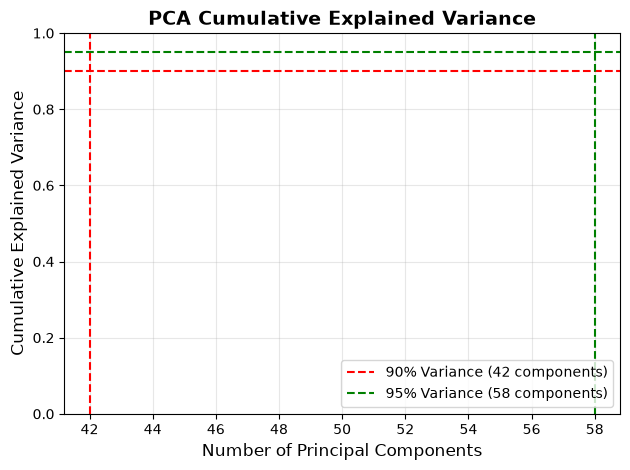

Original number of features (after One-Hot Encoding): 216
Number of components required to preserve 90% variance: 42
Number of components required to preserve 95% variance: 58


In [48]:
# Draw reference lines
plt.axhline(y=0.90, color='r', linestyle='--', label=f'90% Variance ({threshold_90} components)')
plt.axhline(y=0.95, color='g', linestyle='--', label=f'95% Variance ({threshold_95} components)')
plt.axvline(x=threshold_90, color='r', linestyle='--')
plt.axvline(x=threshold_95, color='g', linestyle='--')
plt.title('PCA Cumulative Explained Variance', fontsize=14, fontweight='bold')
plt.xlabel('Number of Principal Components', fontsize=12)
plt.ylabel('Cumulative Explained Variance', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Original number of features (after One-Hot Encoding): {X_train_pca_ready.shape[1]}")
print(f"Number of components required to preserve 90% variance: {threshold_90}")
print(f"Number of components required to preserve 95% variance: {threshold_95}")